## 07 Big data, đạo đức và thiên lệch

Notebook này xem xét ba việc: dữ liệu của dự án có phải big data không và xử lý thế nào khi dữ liệu lớn hơn bộ nhớ, các vấn đề đạo đức khi dùng dữ liệu, và những thiên lệch (bias) trong dữ liệu và trong mô hình.

Đầu vào là `games_reduced.csv`, `games_cleaned.csv`, `games_features.csv` và `models/mo_hinh.joblib`.

### 7.1. Dữ liệu của dự án theo 5V

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import precision_score, recall_score

sns.set_theme(style="whitegrid", palette="Set2")

df = pd.read_csv("../data/processed/games_cleaned.csv", low_memory=False)
data = pd.read_csv("../data/processed/games_features.csv", low_memory=False)

print("Số dòng:", len(df))
print("Bộ nhớ khi nạp vào pandas (MB):", round(df.memory_usage(deep=True).sum() / 1024 ** 2, 1))

Số dòng: 125846
Bộ nhớ khi nạp vào pandas (MB): 75.2


| V | Ý nghĩa | Trong dự án |
|---|---|---|
| Volume | Khối lượng | 125.855 game, file gốc khoảng 400 MB, chạy được trên một máy tính cá nhân |
| Velocity | Tốc độ | Một lần tải về từ Kaggle, không phải dữ liệu cập nhật liên tục |
| Variety | Đa dạng | Có số, ngày tháng, khoảng ước tính và văn bản nhiều nhãn |
| Veracity | Độ tin cậy | Owners chỉ là khoảng ước tính, nhiều dữ liệu thiếu ở các năm gần đây |
| Value | Giá trị | Trả lời 5 câu hỏi nghiên cứu ở cấp độ trò chơi |

Dữ liệu này chưa phải big data vì một máy tính cá nhân xử lý được. Thách thức chính nằm ở Veracity. Các mục dưới đây là những cách làm cơ bản nếu dữ liệu lớn hơn.

### 7.2. Giảm bộ nhớ bằng kiểu dữ liệu

Khi dữ liệu lớn, cách đơn giản nhất là chọn kiểu dữ liệu nhỏ hơn: số nguyên 32 bit thay cho 64 bit, kiểu category cho cột có ít giá trị khác nhau.

In [2]:
truoc = df.memory_usage(deep=True).sum() / 1024 ** 2

gon = df.copy()
for cot in gon.columns:
    if gon[cot].dtype == "int64":
        gon[cot] = gon[cot].astype("int32")
    elif gon[cot].dtype == "float64":
        gon[cot] = gon[cot].astype("float32")
gon["Estimated owners"] = gon["Estimated owners"].astype("category")

# Bỏ các cột văn bản dài nếu phân tích không cần
gon_khong_chu = gon.drop(columns=["Tags", "Categories", "Genres", "Name"])

sau = gon.memory_usage(deep=True).sum() / 1024 ** 2
sau_khong_chu = gon_khong_chu.memory_usage(deep=True).sum() / 1024 ** 2

print("Ban đầu:", round(truoc, 1), "MB")
print("Sau khi đổi kiểu số và category:", round(sau, 1), "MB")
print("Sau khi bỏ thêm 4 cột văn bản:", round(sau_khong_chu, 1), "MB")

Ban đầu: 75.2 MB
Sau khi đổi kiểu số và category: 61.1 MB
Sau khi bỏ thêm 4 cột văn bản: 14.4 MB


Nhận xét: đổi kiểu dữ liệu giảm từ 75,2 MB xuống 61,1 MB. Bỏ 4 cột văn bản còn 14,4 MB. Phần lớn bộ nhớ nằm ở các cột văn bản, nên chỉ đọc những cột cần thiết là cách hiệu quả nhất. Notebook 00 đã làm việc này khi giảm từ 40 xuống 21 cột.

### 7.3. Đọc dữ liệu theo từng phần

Nếu file lớn hơn bộ nhớ thì không thể đọc một lần. Tham số chunksize đọc từng phần, tính kết quả từng phần rồi cộng lại, nên bộ nhớ chỉ cần chứa một phần.

In [3]:
bat_dau = time.time()
tong_dong = 0
so_game_co_ccu = 0
so_phan = 0

for phan in pd.read_csv("../data/processed/games_reduced.csv", chunksize=20000, low_memory=False):
    tong_dong = tong_dong + len(phan)
    so_game_co_ccu = so_game_co_ccu + (phan["Peak CCU"] > 0).sum()
    so_phan = so_phan + 1

print("Số phần đã đọc:", so_phan)
print("Tổng số dòng:", tong_dong)
print("Tỷ lệ game có Peak CCU > 0:", round(so_game_co_ccu / tong_dong * 100, 2), "%")
print("Thời gian (giây):", round(time.time() - bat_dau, 2))

Số phần đã đọc: 7
Tổng số dòng: 125855
Tỷ lệ game có Peak CCU > 0: 15.64 %
Thời gian (giây): 0.51


Nhận xét: đọc 7 phần cho cùng kết quả với đọc một lần (15,64%, đúng với số trong báo cáo giữa kỳ vì file này vẫn chứa nhóm thiếu owners). Cách này dùng được khi kết quả cộng dồn được như tổng và đếm, còn trung vị thì khó hơn.

### 7.4. Lấy mẫu

Với dữ liệu rất lớn, nhiều câu hỏi có thể trả lời từ một mẫu ngẫu nhiên. Phần này so sánh kết quả từ mẫu với kết quả trên toàn bộ dữ liệu.

In [4]:
ket_qua = []
for ty_le in [0.01, 0.05, 0.1, 1.0]:
    mau = data.sample(frac=ty_le, random_state=42)
    ket_qua.append({
        "Tỷ lệ lấy mẫu": ty_le,
        "Số game": len(mau),
        "% có Peak CCU > 0": round(mau["has_ccu"].mean() * 100, 2),
        "Trung vị Positive ratio": round(mau["Positive ratio"].median(), 2),
        "Giá trung vị": round(mau["Price"].median(), 2),
    })
display(pd.DataFrame(ket_qua))

,Tỷ lệ lấy mẫu,Số game,% có Peak CCU > 0,Trung vị Positive ratio,Giá trung vị
0,0.01,1000,20.20,80.73,2.99
1,0.05,5001,19.46,81.18,2.99
2,0.10,10002,19.50,81.30,2.99
3,1.00,100025,19.40,81.27,2.99


Nhận xét: mẫu 10% (10.002 game) cho tỷ lệ 19,50%, gần với 19,40% trên toàn bộ. Mẫu 1% đã lệch 0,8 điểm. Lấy mẫu phù hợp với các câu hỏi về tổng thể, nhưng không phù hợp nếu cần nghiên cứu các game hiếm, ví dụ 10 game miễn phí lớn nhất.

### 7.5. Thiên lệch trong dữ liệu

Phần này đo những thiên lệch có thể đo được. Trước hết là thiếu dữ liệu owners theo giá và theo năm.

Tỷ lệ game thiếu dữ liệu owners (%):


Thời kỳ,Đến 2020,2021-2024,Từ 2025
Loại giá,,,
Miễn phí,1.7,73.5,93.4
Trả phí,0.3,1.9,32.2


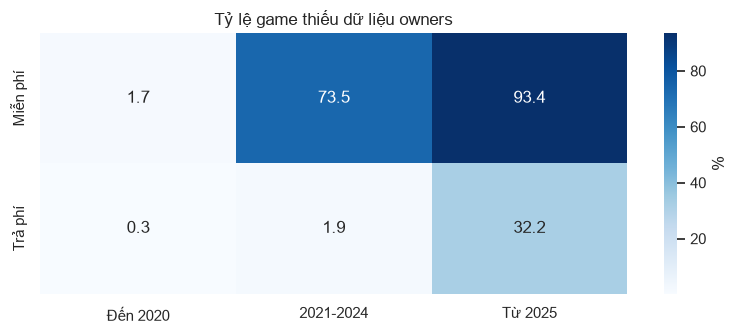

In [5]:
df["Năm"] = pd.to_datetime(df["Release date"]).dt.year
df["thieu_owner"] = df["Estimated owners"] == "0 - 0"
df["Loại giá"] = np.where(df["Price"] == 0, "Miễn phí", "Trả phí")

gd = []
for nam in df["Năm"]:
    if nam <= 2020:
        gd.append("Đến 2020")
    elif nam <= 2024:
        gd.append("2021-2024")
    else:
        gd.append("Từ 2025")
df["Thời kỳ"] = gd

bang_thieu = df.pivot_table(index="Loại giá", columns="Thời kỳ", values="thieu_owner",
                            aggfunc="mean")[["Đến 2020", "2021-2024", "Từ 2025"]] * 100
print("Tỷ lệ game thiếu dữ liệu owners (%):")
display(bang_thieu.round(1))

plt.figure(figsize=(8, 3.5))
sns.heatmap(bang_thieu, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "%"})
plt.title("Tỷ lệ game thiếu dữ liệu owners")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

Tiếp theo là độ phủ của điểm Metacritic và của Positive ratio theo quy mô game. Nếu game lớn có dữ liệu nhiều hơn hẳn thì kết luận từ các cột này nghiêng về game lớn.

In [6]:
quy_mo = []
for so in data["Owners_mid"]:
    if so <= 10000:
        quy_mo.append("Dưới 20 nghìn")
    elif so <= 150000:
        quy_mo.append("20-200 nghìn")
    elif so <= 750000:
        quy_mo.append("200 nghìn-1 triệu")
    else:
        quy_mo.append("Trên 1 triệu")
data["Quy mô"] = quy_mo
thu_tu_quy_mo = ["Dưới 20 nghìn", "20-200 nghìn", "200 nghìn-1 triệu", "Trên 1 triệu"]

bang_phu = data.groupby("Quy mô").agg(
    so_game=("id", "size"),
    pct_co_metacritic=("Metacritic score", lambda s: s.notna().mean() * 100),
    pct_du_10_danh_gia=("Positive ratio", lambda s: s.notna().mean() * 100),
    pct_co_gio_choi=("Median playtime forever", lambda s: (s > 0).mean() * 100),
).reindex(thu_tu_quy_mo)
display(bang_phu.round(1))

,so_game,pct_co_metacritic,pct_du_10_danh_gia,pct_co_gio_choi
Quy mô,,,,
Dưới 20 nghìn,74604,0.8,45.4,12.7
20-200 nghìn,20083,8.2,85.0,56.7
200 nghìn-1 triệu,3991,31.3,98.0,92.7
Trên 1 triệu,1347,53.6,99.6,98.7


Nhận xét:

- Thiếu dữ liệu owners không ngẫu nhiên. Từ 2021 đến 2024 có 73,5% game miễn phí bị thiếu, so với 1,9% game trả phí. Đây là thiên lệch đã làm sai con số về game miễn phí trong báo cáo giữa kỳ.
- Có Metacritic ở 53,6% game trên 1 triệu người sở hữu nhưng chỉ 0,8% game dưới 20 nghìn. So sánh với giới phê bình ở RQ2 vì vậy chủ yếu nói về game lớn.
- Chỉ 45,4% game dưới 20 nghìn người sở hữu có đủ 10 đánh giá và 12,7% có thời gian chơi. RQ2 và RQ3 nghiêng về game đã có người chơi.

Một số thiên lệch khác không đo được bằng dữ liệu này:

- Peak CCU chỉ đo trong một ngày, nên có thể phụ thuộc vào ngày dữ liệu được ghi nhận.
- Một số game lớn ngoài nhóm "0 - 0" cũng có số liệu không hợp lý, ví dụ Portal 2 có hơn 153.000 đánh giá tích cực nhưng owners là "0 - 20000" và Peak CCU = 0. Không có cách tách hết các trường hợp này.
- Người viết đánh giá là những người tự nguyện, thường là người rất thích hoặc rất ghét game.
- Game đã bị gỡ khỏi Steam không có trong dữ liệu, nên các game cũ còn lại thường là game tốt hơn mức trung bình.
- Dữ liệu chỉ có Steam, không đại diện cho console hay điện thoại.

### 7.6. Thiên lệch của mô hình

Mô hình có thể dự đoán tốt cho nhóm này nhưng kém cho nhóm khác. Phần này tính kết quả của Random Forest trên tập test theo từng nhóm game.

,Nhóm,Số game,Tỷ lệ thực tế (%),Tỷ lệ dự đoán (%),Precision,Recall
0,Miễn phí,1954,22.3,34.9,0.416,0.653
1,Trả phí,18051,19.1,32.0,0.414,0.694
2,Có Indie,14359,16.5,27.9,0.365,0.615
3,Không Indie,5646,26.7,43.4,0.496,0.806
4,Trước 2018,3239,30.0,57.5,0.442,0.846
5,2018-2022,8550,17.0,25.5,0.420,0.631
6,Từ 2023,8216,17.7,29.3,0.388,0.643


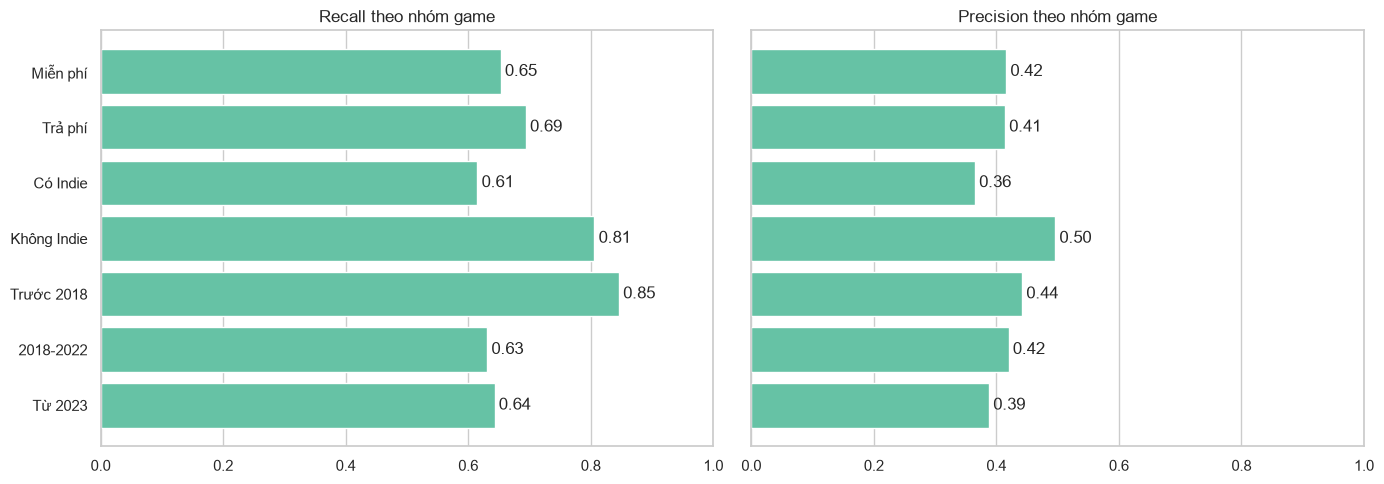

In [7]:
goi = joblib.load("../models/mo_hinh.joblib")
rung = goi["phan_loai"]["Random Forest"]
dac_trung = goi["dac_trung_phan_loai"]

test = data[data["split"] == "test"].copy()
test["du_doan"] = rung.predict(test[dac_trung])

cac_nhom = {
    "Miễn phí": test["is_free"] == 1,
    "Trả phí": test["is_free"] == 0,
    "Có Indie": test["genre_Indie"] == 1,
    "Không Indie": test["genre_Indie"] == 0,
    "Trước 2018": test["Năm phát hành"] < 2018,
    "2018-2022": (test["Năm phát hành"] >= 2018) & (test["Năm phát hành"] <= 2022),
    "Từ 2023": test["Năm phát hành"] >= 2023,
}

ket_qua = []
for ten, dieu_kien in cac_nhom.items():
    nhom = test[dieu_kien]
    ket_qua.append({
        "Nhóm": ten,
        "Số game": len(nhom),
        "Tỷ lệ thực tế (%)": round(nhom["has_ccu"].mean() * 100, 1),
        "Tỷ lệ dự đoán (%)": round(nhom["du_doan"].mean() * 100, 1),
        "Precision": round(precision_score(nhom["has_ccu"], nhom["du_doan"], zero_division=0), 3),
        "Recall": round(recall_score(nhom["has_ccu"], nhom["du_doan"], zero_division=0), 3),
    })

bang_cong_bang = pd.DataFrame(ket_qua)
display(bang_cong_bang)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].barh(bang_cong_bang["Nhóm"], bang_cong_bang["Recall"])
axes[0].bar_label(axes[0].containers[0], fmt="%.2f", padding=3)
axes[0].set(title="Recall theo nhóm game", xlim=(0, 1))
axes[0].invert_yaxis()
axes[1].barh(bang_cong_bang["Nhóm"], bang_cong_bang["Precision"])
axes[1].bar_label(axes[1].containers[0], fmt="%.2f", padding=3)
axes[1].set(title="Precision theo nhóm game", xlim=(0, 1))
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Nhận xét:

- Mô hình hoạt động không đều. Recall ở game không có nhãn Indie là 0,806, ở game Indie là 0,615. Game phát hành trước 2018 có recall 0,846, trong khi các game mới hơn khoảng 0,63-0,64.
- Precision của game Indie thấp nhất trong bảng (0,365). Nếu dùng mô hình này để chọn game đáng chú ý, game Indie và game mới sẽ dễ bị bỏ sót hơn.
- Mô hình dự đoán tỷ lệ dương cao hơn thực tế ở mọi nhóm, ví dụ 57,5% so với 30,0% ở game trước 2018. Đây là hệ quả của class_weight="balanced".
- Game miễn phí và trả phí có kết quả khá gần nhau, nhưng tập test chỉ có 1.954 game miễn phí và phần lớn là game cũ.

### 7.7. Đạo đức khi sử dụng dữ liệu

- Quyền riêng tư: mỗi dòng là một trò chơi, không có thông tin của người chơi. Cột Support email đã bị bỏ ở notebook 00. Rủi ro về dữ liệu cá nhân thấp.
- Nguồn dữ liệu: dữ liệu lấy từ Kaggle, nhóm cần đọc giấy phép trên trang bộ dữ liệu trước khi chia sẻ lại, vì repo đang chứa file `games_reduced.csv`.
- Minh bạch: mọi bước sửa dữ liệu được ghi vào cleaning log. Khi phát hiện giả định về owners = "0 - 0" sai, nhóm cần nói rõ và sửa kết luận thay vì giữ nguyên.
- Diễn giải: mọi kết quả chỉ là mối liên hệ. Nói rằng game nên tăng giá hoặc thêm Achievements để thành công là vượt quá những gì dữ liệu cho phép.
- Tác động: nếu mô hình được dùng để quyết định đầu tư hay gợi ý game, nhà phát triển nhỏ và game mới có thể bị thiệt, khiến game lớn càng được chú ý. Mô hình của nhóm không nên dùng cho mục đích này.

### 7.8. Kết luận

- Dữ liệu chưa phải big data, các kỹ thuật đọc theo phần, đổi kiểu dữ liệu và lấy mẫu vẫn dùng được nếu dữ liệu tăng lên.
- Thiên lệch quan trọng nhất là thiếu dữ liệu owners ở game miễn phí và game mới.
- Khi đọc kết quả của dự án cần nhớ các phần về Metacritic, đánh giá và thời gian chơi chủ yếu đại diện cho game đã có người chơi.

#### Lưu bảng kết quả

In [8]:
# Lưu các bảng chính để dùng trong báo cáo
bang_thieu.to_csv("../reports/tables/ty_le_thieu_owners.csv", encoding="utf-8-sig")
bang_phu.to_csv("../reports/tables/do_phu_theo_quy_mo.csv", encoding="utf-8-sig")
bang_cong_bang.to_csv("../reports/tables/ket_qua_theo_nhom_game.csv", encoding="utf-8-sig")
print("Đã lưu bảng vào reports/tables")

Đã lưu bảng vào reports/tables
